# BodyM: chạy thử baseline số đo cơ thể
Dự đoán vòng ngực, eo, hông từ hai silhouette và chiều cao/cân nặng/giới tính.
So sánh giá trị trung bình, Ridge chỉ dùng metadata và Ridge có thêm đặc trưng ảnh.
Chia 20% người trong train làm validation (seed 42), chọn alpha trên validation, rồi huấn luyện lại trên toàn bộ train.
MAE được tính trung bình trong mỗi người, sau đó trung bình giữa các người.
Hai tập test được báo cáo riêng vì dữ liệu gốc có chung 1 subject_id.

In [1]:
from pathlib import Path
import csv, json, pickle, subprocess, sys
import numpy as np
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/run_bodym_baseline.py').exists())
OUTPUT = ROOT / 'experiments/bodym_baseline'
print('Project:', ROOT)

Project: F:\code\healthcare-ai-research


In [2]:
# Đổi thành True để trích xuất ảnh và huấn luyện lại toàn bộ.
RUN_TRAINING = False
if RUN_TRAINING or not (OUTPUT / 'metrics.json').exists():
    subprocess.run([sys.executable, str(ROOT / 'scripts/run_bodym_baseline.py')], cwd=ROOT, check=True)
report = json.loads((OUTPUT / 'metrics.json').read_text(encoding='utf-8'))
print('Run:', report['created_at_utc'])
print('Fit / validation subjects:', report['fit_subjects'], '/', report['validation_subjects'])
print('Feature count:', report['feature_count'])

Run: 2026-10-18T06:12:09.982413+00:00
Fit / validation subjects: 1614 / 404
Feature count: 393


# BodyM baseline run

Fit: 1614 subjects; validation: 404 subjects.

Targets: chest, waist, hip (cm). Test models refitted on all 2,018 training subjects.

MAE below gives each subject equal weight, including subjects with multiple photos.

| Model | Split | Chest MAE (cm) | Waist MAE (cm) | Hip MAE (cm) | Mean MAE (cm) |
| --- | --- | ---: | ---: | ---: | ---: |
| mean_baseline | validation | 8.188 | 9.712 | 6.783 | 8.227 |
| mean_baseline | testA | 8.070 | 9.631 | 7.010 | 8.237 |
| mean_baseline | testB | 10.775 | 11.999 | 8.355 | 10.376 |
| metadata_ridge | validation | 2.872 | 3.478 | 2.292 | 2.881 |
| metadata_ridge | testA | 2.903 | 3.306 | 2.018 | 2.742 |
| metadata_ridge | testB | 3.277 | 3.561 | 2.446 | 3.095 |
| silhouette_metadata_ridge | validation | 2.236 | 2.788 | 1.957 | 2.327 |
| silhouette_metadata_ridge | testA | 2.284 | 2.613 | 1.840 | 2.246 |
| silhouette_metadata_ridge | testB | 2.952 | 3.719 | 2.399 | 3.023 |



Limitations:
- Uses supplied height, weight and sex metadata as inputs; this is not an image-only model.
- Uses simple silhouette profiles and Ridge regression, not the published BMnet model.
- Original testA and testB share one subject ID; report their results separately.
- Does not predict InBody values, body-fat percentage or skeletal muscle mass.
- The score is an initial experiment, not a clinical validation.


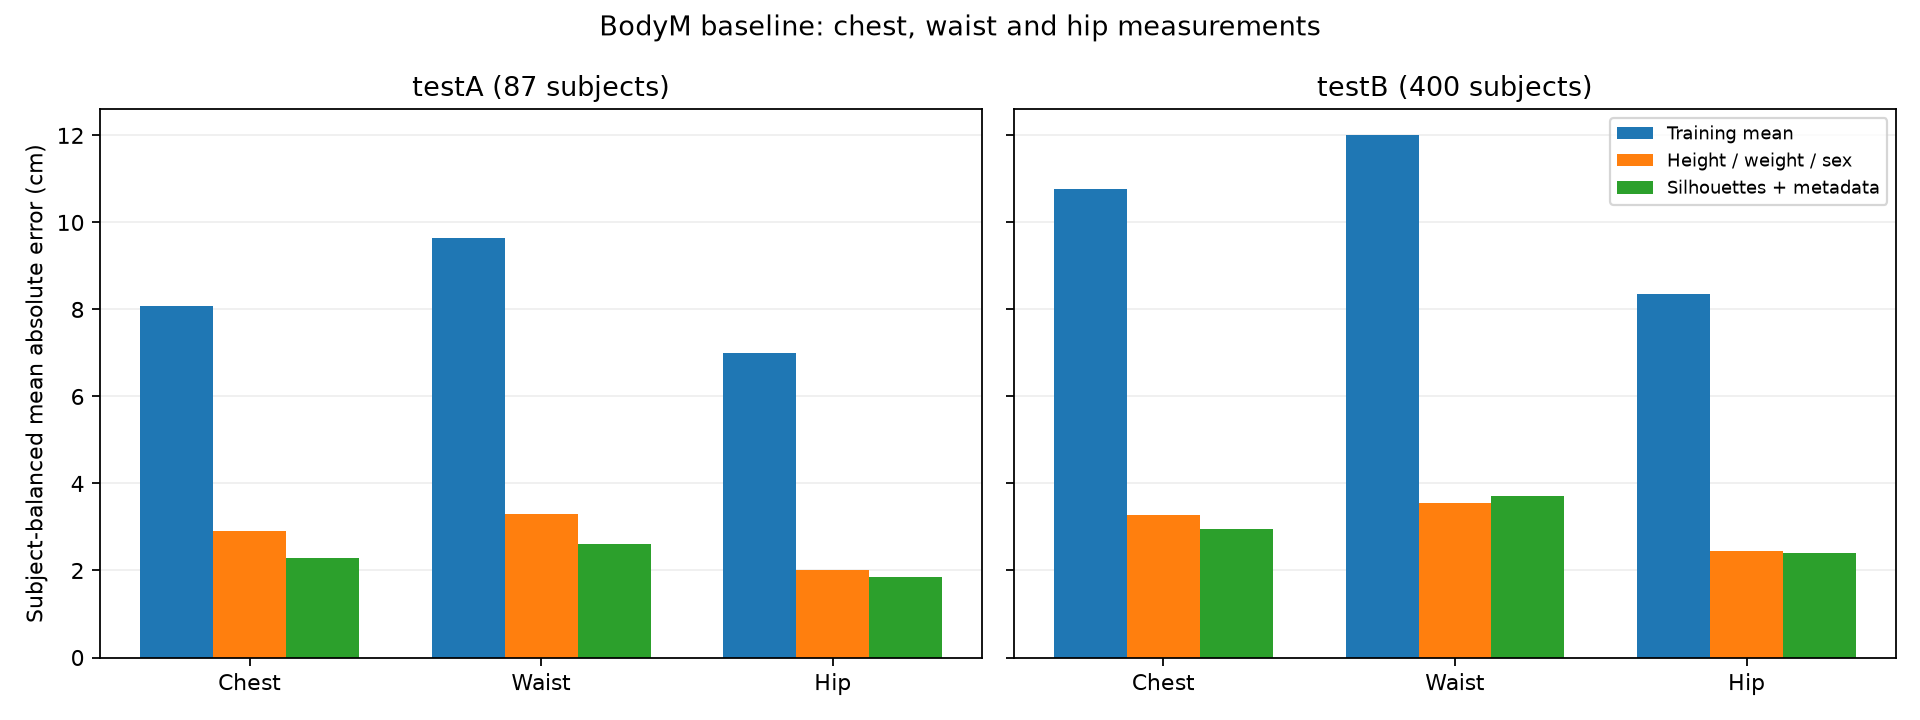

In [3]:
text = (OUTPUT / 'report.md').read_text(encoding='utf-8')
display(Markdown(text.replace('![MAE comparison](mae_comparison.png)', '')))
display(Image(filename=str(OUTPUT / 'mae_comparison.png')))

## Dự đoán bằng mô hình đã lưu
Một cặp ảnh đầu tiên trong testA để minh họa; dùng bảng MAE phía trên để đánh giá toàn tập.

chest: true=97.74 cm, predicted=94.22 cm, error=3.52 cm
waist: true=80.65 cm, predicted=79.06 cm, error=1.59 cm
hip: true=98.07 cm, predicted=96.41 cm, error=1.65 cm


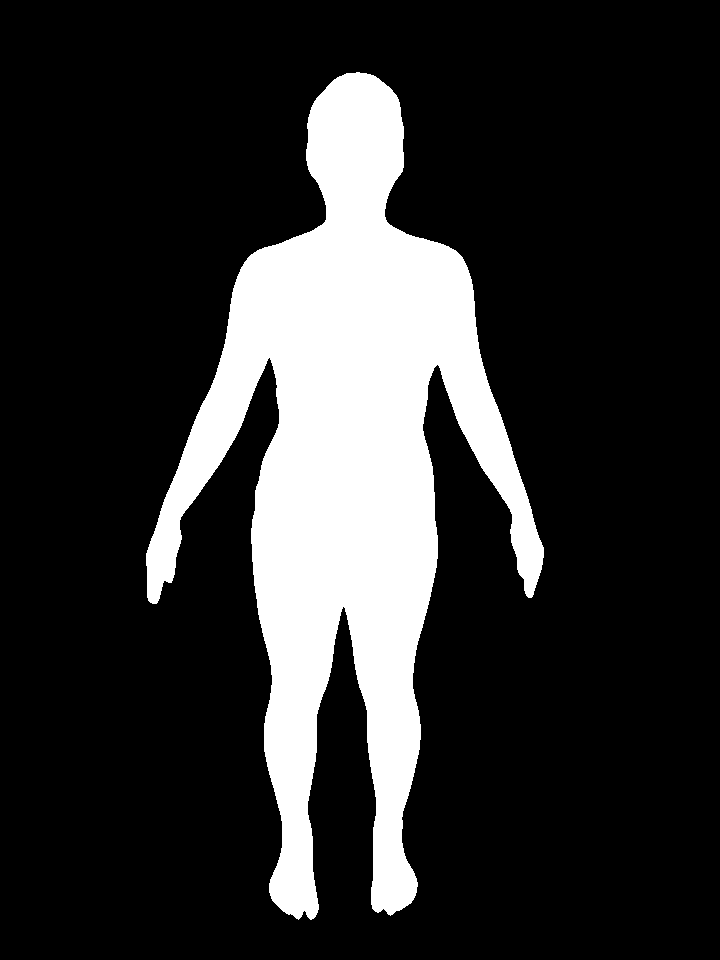

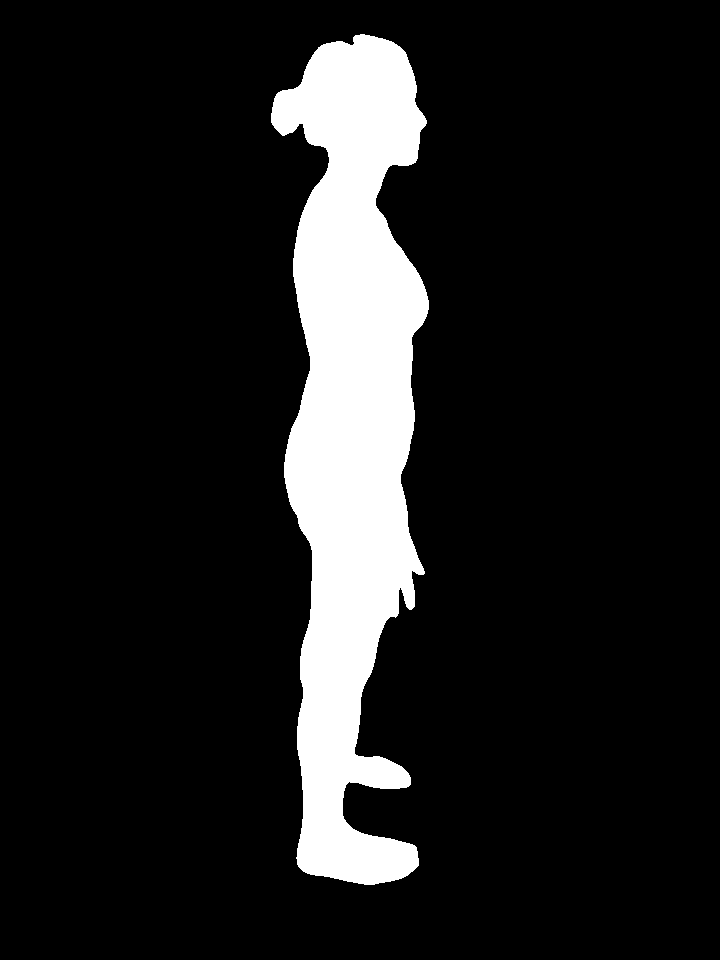

In [4]:
with (ROOT / 'models/bodym_baseline/ridge_models.pkl').open('rb') as handle:
    saved = pickle.load(handle)
with np.load(ROOT / 'data/processed/bodym/testA_features.npz') as data:
    X = data['X'][:1].copy()
    truth = data['y'][0].copy()
    photo_id = str(data['photo_ids'][0])
entry = saved['silhouette_metadata_ridge']
scaler, regressor = entry['model']
prediction = regressor.predict(scaler.transform(X[:, :entry['columns']]))[0]
for target, actual, estimated in zip(saved['target_names'], truth, prediction):
    print(f'{target}: true={actual:.2f} cm, predicted={estimated:.2f} cm, error={abs(actual-estimated):.2f} cm')
for view in ('mask', 'mask_left'):
    display(Image(filename=str(ROOT / 'data/raw/bodym/testA' / view / (photo_id + '.png')), width=180))